In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# 1. Load the cleaned dataset we created in Phase 1
data_path = Path("../data/processed/omni2_cleaned.csv") if Path("../data/processed").exists() else Path("data/processed/omni2_cleaned.csv")
df = pd.read_csv(data_path, parse_dates=["Timestamp"], index_col="Timestamp")

print(f" Loaded cleaned dataset: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

# 2. Select key scientific features for statistical analysis
key_features = [
    "Scalar_B", "BZ_GSM", "Flow_Speed", 
    "Proton_Density", "Temperature", "Flow_Pressure", 
    "Electric_Field", "Dst_index"
]

# 3. Compute Module S-1 Statistical Measures (Central Tendency, Spread, Shape)
stats_summary = pd.DataFrame(index=key_features)

stats_summary["Mean"] = df[key_features].mean()
stats_summary["Median"] = df[key_features].median()
stats_summary["Std_Dev"] = df[key_features].std()
stats_summary["Variance"] = df[key_features].var()
stats_summary["IQR"] = df[key_features].quantile(0.75) - df[key_features].quantile(0.25)
stats_summary["Skewness"] = df[key_features].skew()
stats_summary["Kurtosis"] = df[key_features].kurtosis()

print(" STATISTICAL SUMMARY (Measures of Central Tendency, Dispersion & Shape):")
stats_summary.round(2)

 Loaded cleaned dataset: 52,584 rows × 12 columns

 STATISTICAL SUMMARY (Measures of Central Tendency, Dispersion & Shape):


,Mean,Median,Std_Dev,Variance,IQR,Skewness,Kurtosis
Scalar_B,5.25,4.70,2.59,6.730000e+00,2.60,2.46,11.86
BZ_GSM,-0.13,-0.20,2.66,7.050000e+00,2.70,0.19,8.07
Flow_Speed,410.32,391.00,85.65,7.335990e+03,116.00,0.94,0.55
Proton_Density,6.31,5.00,4.73,2.236000e+01,4.61,2.80,15.18
Temperature,81711.14,57691.50,78944.20,6.232186e+09,72513.25,4.23,47.95
Flow_Pressure,1.80,1.50,1.24,1.540000e+00,1.07,3.53,25.27
Electric_Field,0.06,0.06,1.13,1.290000e+00,1.08,0.04,13.59
Dst_index,-8.51,-6.00,14.40,2.074300e+02,15.00,-2.09,13.55


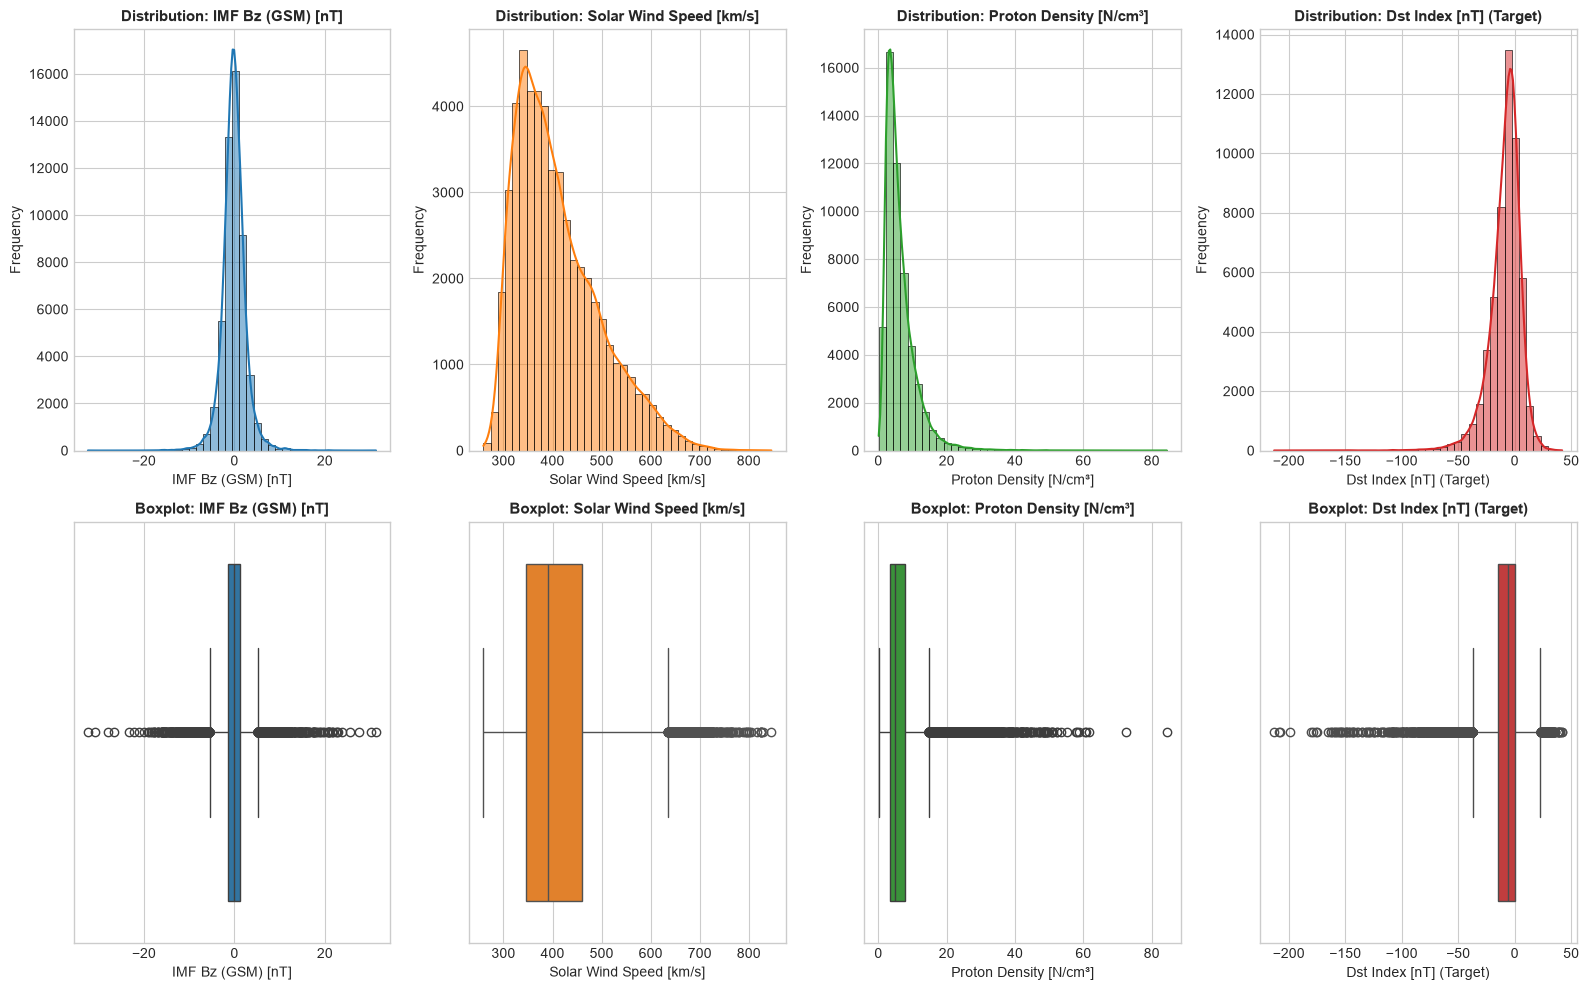

 Distribution and outlier plots successfully rendered!


In [4]:
# Set up a clean, publication-style visualization grid
plt.figure(figsize=(16, 10))
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")

plot_features = [
    ("BZ_GSM", "IMF Bz (GSM) [nT]", "#1f77b4"),
    ("Flow_Speed", "Solar Wind Speed [km/s]", "#ff7f0e"),
    ("Proton_Density", "Proton Density [N/cm³]", "#2ca02c"),
    ("Dst_index", "Dst Index [nT] (Target)", "#d62728")
]

for idx, (col, title, color) in enumerate(plot_features, 1):
    # Top row: Histograms with KDE (Kernel Density Estimate)
    plt.subplot(2, 4, idx)
    sns.histplot(df[col], kde=True, color=color, bins=40)
    plt.title(f"Distribution: {title}", fontsize=11, fontweight="bold")
    plt.xlabel(title, fontsize=10)
    plt.ylabel("Frequency", fontsize=10)
    
    # Bottom row: Boxplots to highlight outliers / tails
    plt.subplot(2, 4, idx + 4)
    sns.boxplot(x=df[col], color=color)
    plt.title(f"Boxplot: {title}", fontsize=11, fontweight="bold")
    plt.xlabel(title, fontsize=10)

plt.tight_layout()
plt.show()
print(" Distribution and outlier plots successfully rendered!")